In [49]:
import numpy as np
import pandas as pd

Import the dataset "Drugs A, B, C, X, Y for Decision Trees"

Description: Imagine that you are a medical researcher compiling data for a study. You have collected data about a set of patients, all of whom suffered from the same illness. During their course of treatment, each patient responded to one of 5 medications, Drug A, Drug B, Drug c, Drug x and y.

Part of your job is to build a model to find out which drug might be appropriate for a future patient with the same illness. The features of this dataset are Age, Sex, Blood Pressure, and the Cholesterol of the patients, and the target is the drug that each patient responded to.

It is a sample of multiclass classifier, and you can use the training part of the dataset to build a decision tree, and then use it to predict the class of a unknown patient, or to prescribe a drug to a new patient.

DATA Source: IBM

In [50]:
# import the dataset
df = pd.read_csv('drug200.csv')
# print the first 5 rows
print(df.head())

   Age Sex      BP Cholesterol  Na_to_K   Drug
0   23   F    HIGH        HIGH   25.355  drugY
1   47   M     LOW        HIGH   13.093  drugC
2   47   M     LOW        HIGH   10.114  drugC
3   28   F  NORMAL        HIGH    7.798  drugX
4   61   F     LOW        HIGH   18.043  drugY


A decision tree is a Machine Learning's Algorithm which divides the feature's space into the most correct and purest groups.


It's based on a simple idea: **Splitting**


We have to split a node into 2 leaves which helps to increase the accuracy of the prediction.


We use the Gini's Impurity to evaluate the error of a split;


$ Gini(D)= 1 - \sum_{k=1}^{K}p_{k}^{2} $

$p_{k}$ is the elements proportion which live in the class k of node D

The tree chooses the features and the splits which maximise $\Delta Gini = Gini(D) - (\frac{|D_{left}|}{|D|}Gini(D_{left})+\frac{|D_{right}|}{|D|}Gini(D_{right}))$

In [51]:
def gini_impurity(y):
    # if group null return 0
    if len(y) == 0:
        return 0.0
    
    # y into a pandas Series 
    if not isinstance(y, pd.Series):
        y = pd.Series(y)
        
    # relative frequencies of each class
    proportions = y.value_counts(normalize=True)

    # sum(p_i^2)
    gini = 1.0 - np.sum(proportions**2)
     
    return gini

In [52]:
def information_gain(y_parent, y_left, y_right):
    # Impurity of the parent node
    gini_parent = gini_impurity(y_parent)
    
    # weights of the child node (proportion)
    n_total = len(y_parent)
    n_left = len(y_left)
    n_right = len(y_right)
    
    # control if one node is empty
    if n_left == 0 or n_right == 0:
        return 0.0
    
    weight_left = n_left / n_total
    weight_right = n_right / n_total
    
    # right part of the formula
    gini_children = weight_left * gini_impurity(y_left) + weight_right * gini_impurity(y_right)

    # Information Gain
    gain = gini_parent - gini_children

    return gain

In [53]:
def bestcut_feature(X_column, y):

    best_gain = -1.0
    best_threshold = None
    
    # unique values to check for potential cuts
    possibility = np.unique(X_column)
    
    for threshold in possibility:
        # divide elements
        mask_left = X_column <= threshold
        
        y_left = y[mask_left]
        y_right = y[~mask_left]
        
        # Information Gain
        gain = information_gain(y, y_left, y_right)
        
        # save in case of best gain
        if gain > best_gain:
            best_gain = gain
            best_threshold = threshold
            
    return best_threshold, best_gain

Working with Categorical Features

In [54]:
# Copy of the dataset
df_encoded = df.copy()

# Ordinal Encoding for BP and Cholesterol
# logic order of importance
bp_mapping = {'LOW': 0, 'NORMAL': 1, 'HIGH': 2}
chol_mapping = {'NORMAL': 0, 'HIGH': 1}

df_encoded['BP'] = df_encoded['BP'].map(bp_mapping)
df_encoded['Cholesterol'] = df_encoded['Cholesterol'].map(chol_mapping)

# Encoding for Sex (binary variable)
sex_mapping = {'F': 0, 'M': 1}
df_encoded['Sex'] = df_encoded['Sex'].map(sex_mapping)

# Encoding Target 'Drug'
drug_mapping = {'drugA': 0, 'drugB': 1, 'drugC': 2, 'drugX': 3, 'drugY': 4}
df_encoded['Drug'] = df_encoded['Drug'].map(drug_mapping)

print("first 5 new rows")
print(df_encoded.head())

first 5 new rows
   Age  Sex  BP  Cholesterol  Na_to_K  Drug
0   23    0   2            1   25.355     4
1   47    1   0            1   13.093     2
2   47    1   0            1   10.114     2
3   28    0   1            1    7.798     3
4   61    0   0            1   18.043     4


In [55]:
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

df_sklearn = df.copy()

# Imput feature (BP, Cholesterol, Sex)
encoder = OrdinalEncoder()
df_sklearn[['Sex', 'BP', 'Cholesterol']] = encoder.fit_transform(df_sklearn[['Sex', 'BP', 'Cholesterol']])

# Target (Drug)
label_encoder = LabelEncoder()
df_sklearn['Drug'] = label_encoder.fit_transform(df_sklearn['Drug'])

print(df_sklearn.head())

   Age  Sex   BP  Cholesterol  Na_to_K  Drug
0   23  0.0  0.0          0.0   25.355     4
1   47  1.0  1.0          0.0   13.093     2
2   47  1.0  1.0          0.0   10.114     2
3   28  0.0  2.0          0.0    7.798     3
4   61  0.0  1.0          0.0   18.043     4


In [56]:
# Input Features (Age, Sex, BP, Cholesterol, Na_to_K)
X = df_encoded.drop(columns=['Drug'])

# Target (Drug)
y = df_encoded['Drug']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (200, 5)
Shape of y: (200,)


Accuracy of the Decision Tree on Test Set: 97.50%



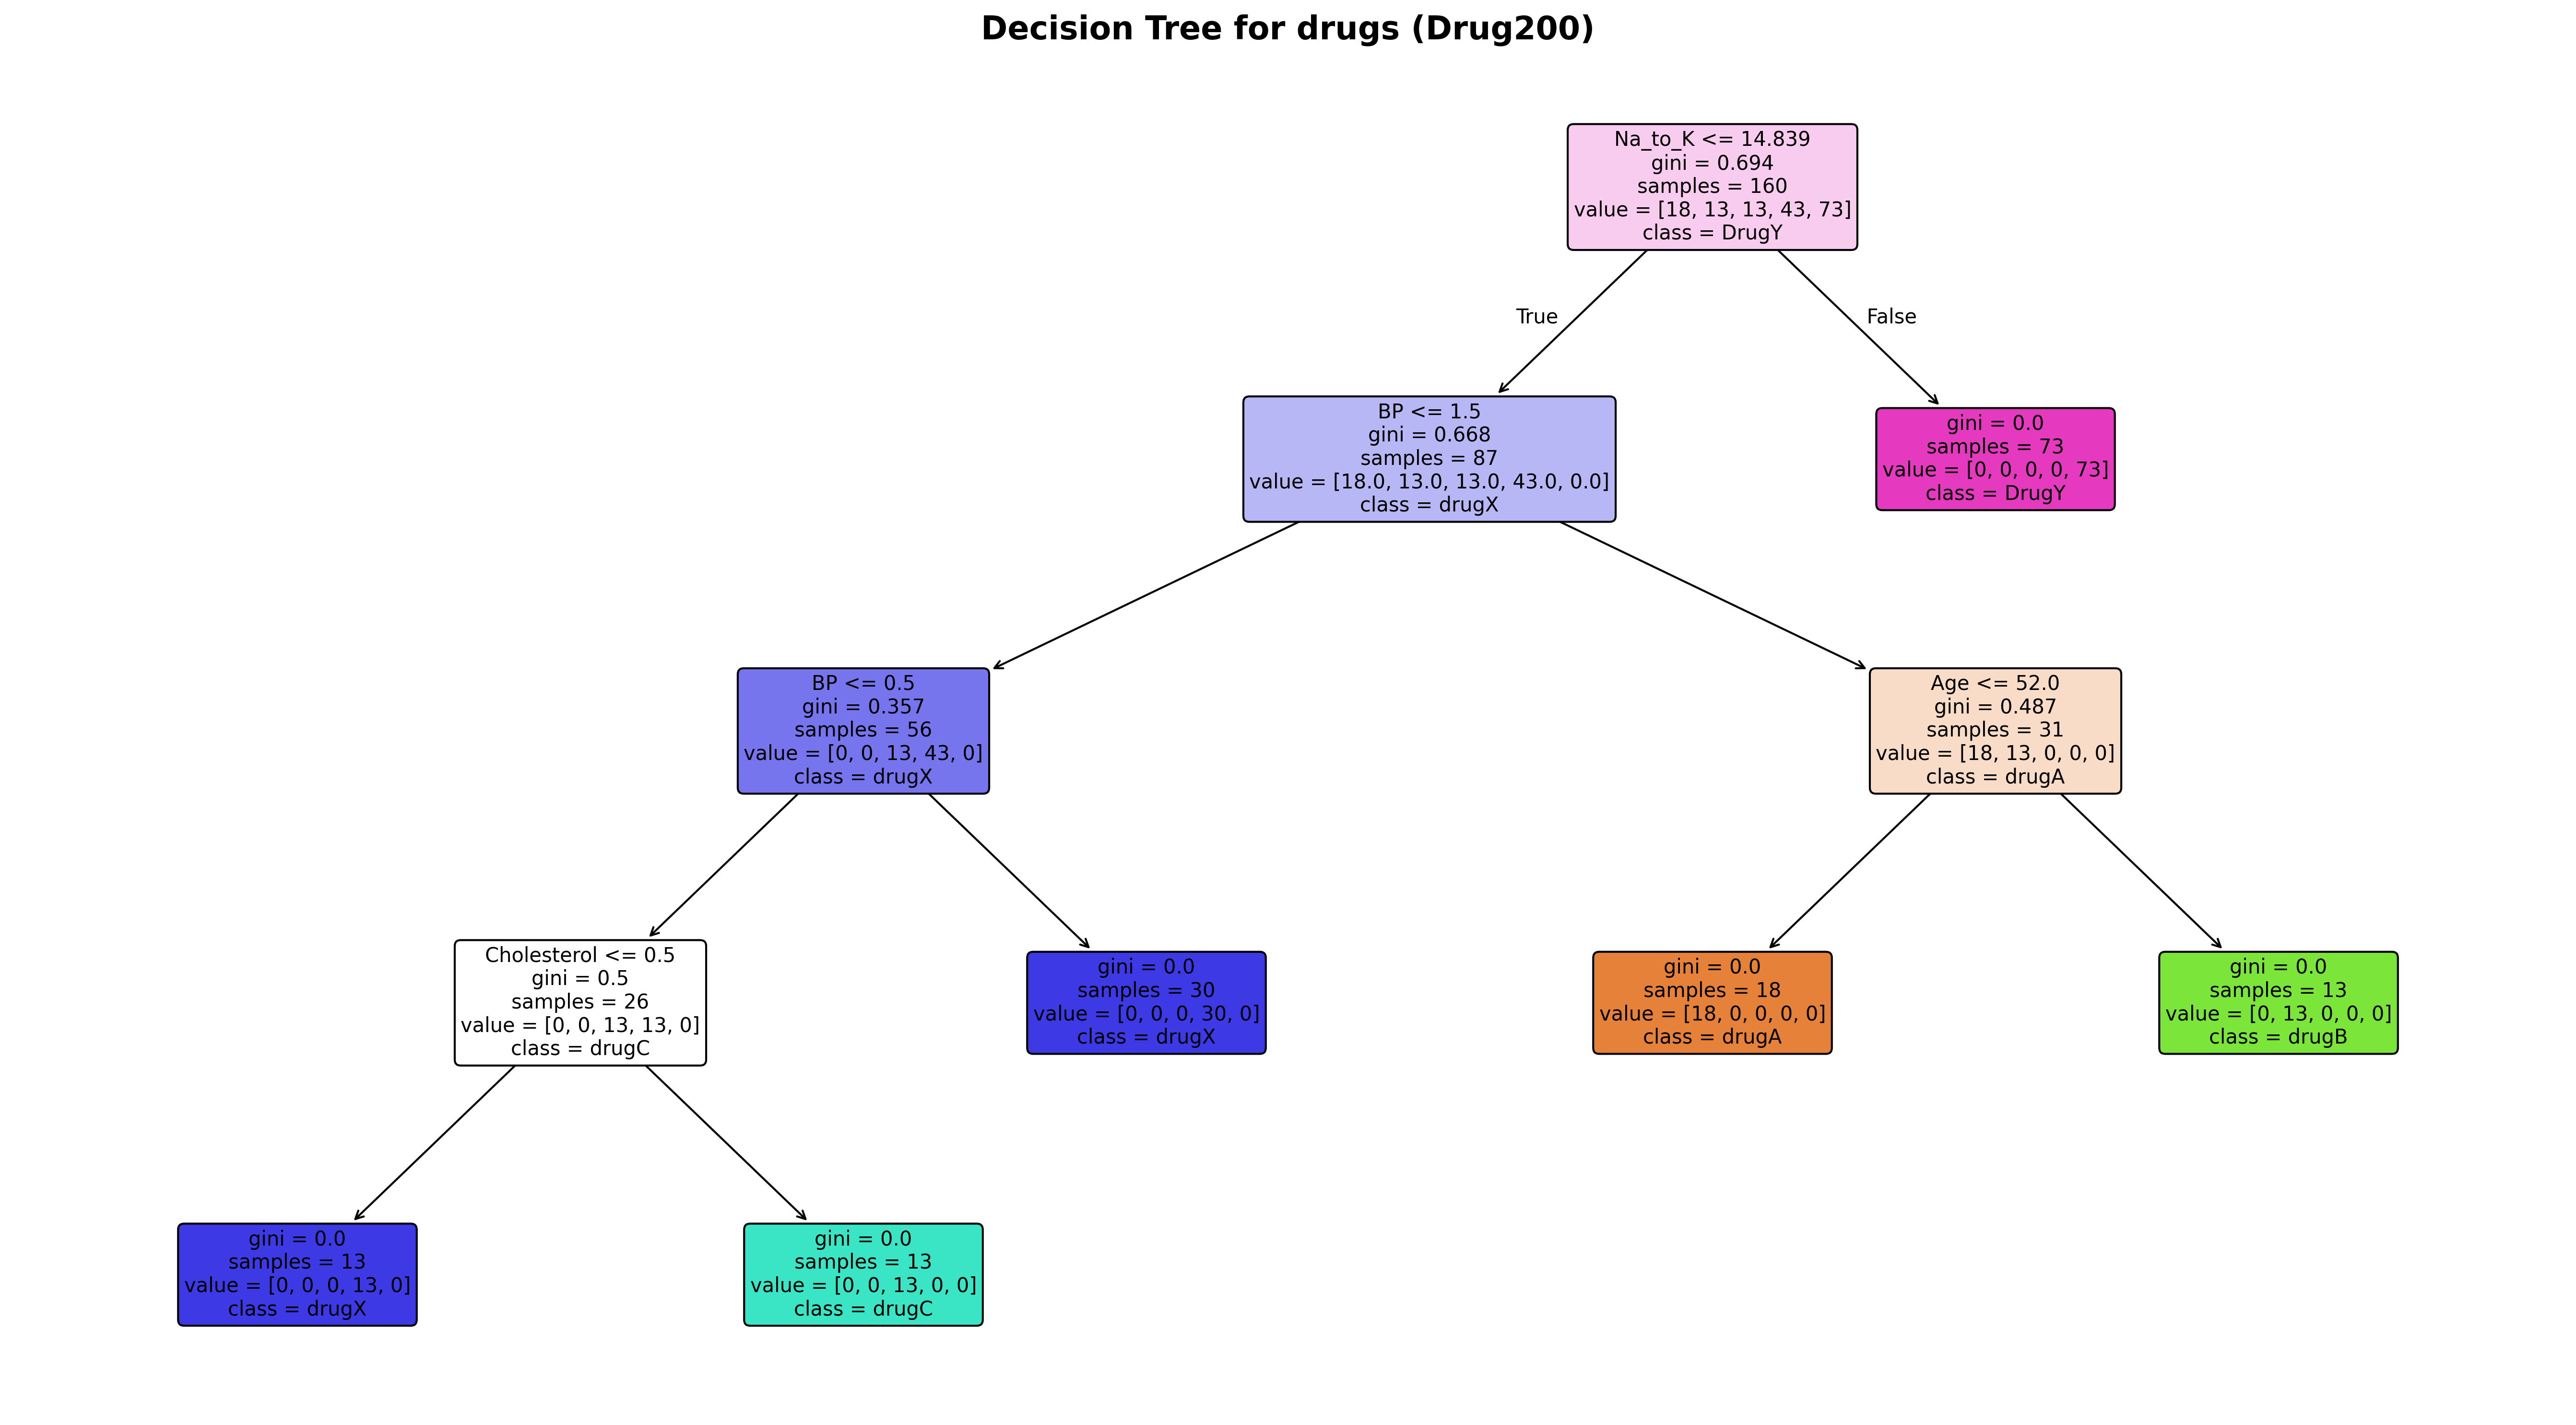

In [57]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# Divide Train Set (80%) amd Test Set (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# model
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

# Training
dt_model.fit(X_train, y_train)

# Accuracy on Test Set
y_pred = dt_model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy of the Decision Tree on Test Set: {acc:.2%}\n")

# Original class names
class_names = ['drugA', 'drugB', 'drugC', 'drugX', 'DrugY']
feature_names = list(X.columns)

# Visualization
plt.figure(figsize=(18, 10), dpi=300)
plot_tree(
    dt_model,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,             
    rounded=True,            
    fontsize=10,             
    impurity=True            
)
plt.title("Decision Tree for drugs (Drug200)", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## Feature Importance

$$Importance(f) = \frac{\sum_{n \; nodes \; with \; f} \Delta Gini(n)|D_{n}|}{\sum_{all  \; nodes \; m} \Delta Gini(m)|D_{m}|}$$

--- Feature Importance ---
Na_to_K             : 0.4762 (47.62%)
BP                  : 0.2706 (27.06%)
Age                 : 0.1360 (13.60%)
Cholesterol         : 0.1171 (11.71%)
Sex                 : 0.0000 (0.00%)


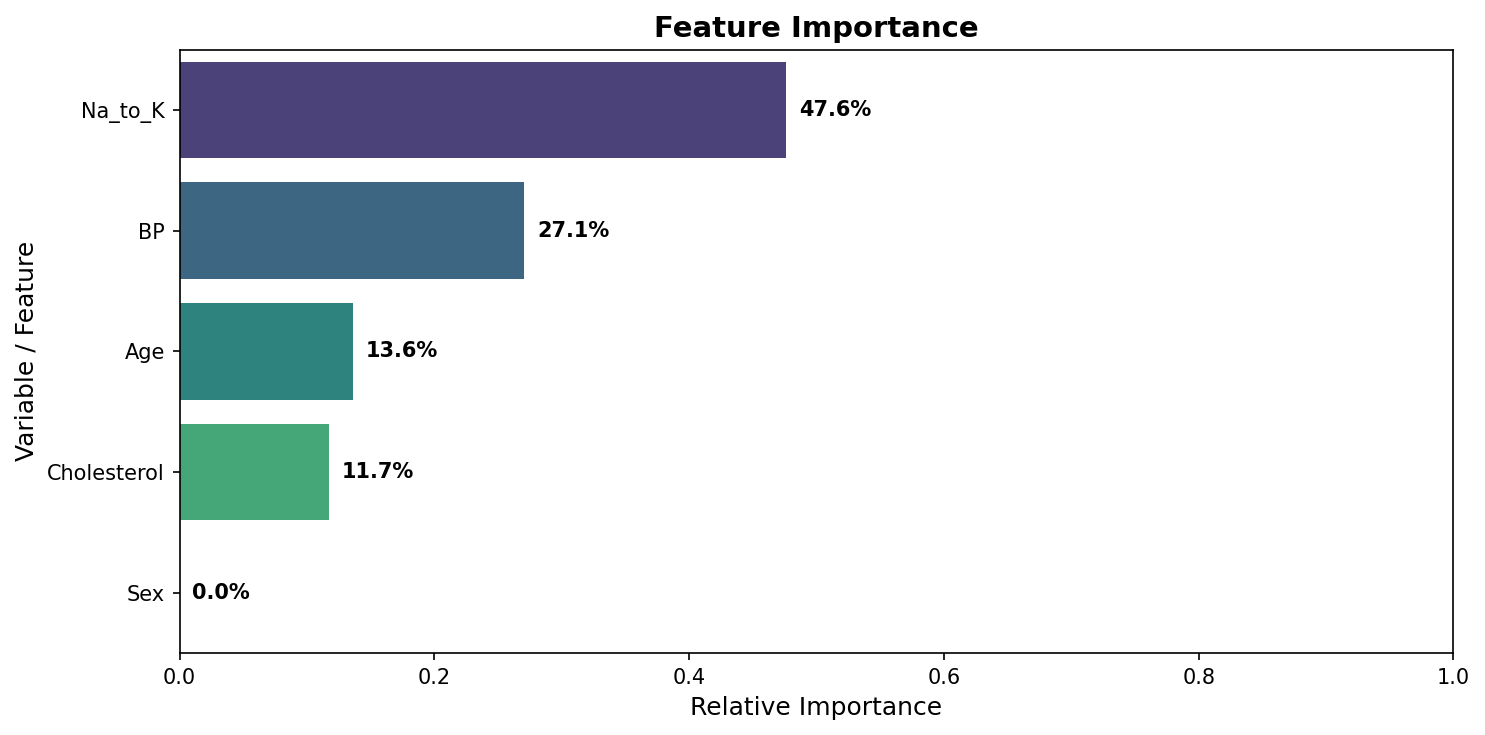

In [58]:
import seaborn as sns

# Feature Importance
importance = dt_model.feature_importances_

df_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)


print("--- Feature Importance ---")
for index, row in df_importance.iterrows():
    print(f"{row['Feature']:<20}: {row['Importance']:.4f} ({row['Importance']*100:.2f}%)")

# Visualization
plt.figure(figsize=(10, 5), dpi=150)
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=df_importance, 
    palette='viridis',
    hue='Feature',
    legend=False
)

# Personalization
plt.title('Feature Importance', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance', fontsize=12)
plt.ylabel('Variable / Feature', fontsize=12)
plt.xlim(0, 1.0) # total = 1.0

for index, value in enumerate(df_importance['Importance']):
    plt.text(value + 0.01, index, f"{value*100:.1f}%", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## RANDOM FORESTS & XGBOOST

## Random Forest (Bootstrap Aggregating / Bagging)

A **Random Forest** is an ensemble method that builds multiple independent decision trees in parallel and combines their predictions.

**Bootstrap Sampling:** Given a dataset $D$ with $N$ samples, the algorithm creates $B$ unique bootstrap subsets ($D_1, D_2, \dots, D_B$) by randomly sampling $N$ observations **with replacement**. Each tree is trained on its own subset.
**Feature Subsampling:** At each split in a tree, instead of evaluating all $p$ features, the algorithm considers only a random subset of $m$ features (typically $m = \sqrt{p}$ for classification). This decorrelates the trees.
**Aggregation (Voting):** For a new input $x$, each tree outputs a vote $\hat{y}_b$. The final prediction is determined by majority vote:

$$\hat{y}_{\text{Forest}} = \text{mode}\left( \{ \hat{y}_1(x), \hat{y}_2(x), \dots, \hat{y}_B(x) \} \right)$$

Random Forests reduce **variance** without increasing bias. They are highly robust against overfitting, require very little hyperparameter tuning, and perform exceptionally well on small-to-medium datasets.

---

## XGBoost (Extreme Gradient Boosting)

Unlike Random Forests—where trees are built independently—**XGBoost** builds trees **sequentially**. Each new tree attempts to correct the errors (residuals) made by the ensemble of previous trees.

At iteration $t$, XGBoost minimizes a regularized objective function:

$$\mathcal{L}^{(t)} = \sum_{i=1}^{n} l\left(y_i, \hat{y}_i^{(t-1)} + f_t(x_i)\right) + \Omega(f_t)$$

Where:
* $l$ is the loss function (e.g., Log-Loss for classification).
* $f_t(x_i)$ is the prediction of the new tree being added.
* $\Omega(f_t) = \gamma T + \frac{1}{2} \lambda \sum_{j=1}^{T} w_j^2$ is the **regularization term** that penalizes complex trees ($T$ is the number of leaves, $w_j$ are leaf weights).

#### Second-Order Taylor Expansion
To solve this efficiently, XGBoost approximates the loss function using a 2nd-order Taylor expansion:

$$\mathcal{L}^{(t)} \approx \sum_{i=1}^{n} \left[ l(y_i, \hat{y}_i^{(t-1)}) + g_i f_t(x_i) + \frac{1}{2} h_i f_t^2(x_i) \right] + \Omega(f_t)$$

Where:
* $g_i = \frac{\partial l(y_i, \hat{y}^{(t-1)})}{\partial \hat{y}^{(t-1)}}$ is the **1st-order gradient** (direction of error).
* $h_i = \frac{\partial^2 l(y_i, \hat{y}^{(t-1)})}{\partial (\hat{y}^{(t-1)})^2}$ is the **2nd-order gradient (Hessian)** (curvature of error).


XGBoost primarily reduces **bias**. It uses gradients to aggressively minimize prediction errors, making it fast, accurate, and powerful on large datasets. However, on tiny datasets, it requires careful hyperparameter tuning (like learning rate and regularization) to avoid overfitting.

In [59]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

RANDOM FOREST

In [60]:
start_rf = time.time()

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    random_state=42
)
rf_model.fit(X_train, y_train)

time_rf = time.time() - start_rf
y_pred_rf = rf_model.predict(X_test)

# Metrics Random Forest
acc_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average='macro')

XGBOOST

In [61]:
start_xgb = time.time()

# Per la classificazione multi-classe, XGBoost usa objective='multi:softprob'
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    eval_metric='mlogloss',
    random_state=42
)
xgb_model.fit(X_train, y_train)

time_xgb = time.time() - start_xgb
y_pred_xgb = xgb_model.predict(X_test)

# Metrics XGBoost
acc_xgb = accuracy_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb, average='macro')

In [62]:
df_confronto = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [f"{acc_rf:.2%}", f"{acc_xgb:.2%}"],
    'F1-Score (Macro)': [f"{f1_rf:.4f}", f"{f1_xgb:.4f}"],
    'Training Time (s)': [f"{time_rf:.4f}", f"{time_xgb:.4f}"]
})

print("=== Comparison ===")
print(df_confronto.to_string(index=False))

=== Comparison ===
        Model Accuracy F1-Score (Macro) Training Time (s)
Random Forest   97.50%           0.9418            0.0801
      XGBoost   87.50%           0.7950            0.0771
